# PathPack v0.7

Учебный репозиторий показывает, чем первый фрагмент файла в v0.7 отличается от чанка v0.4. Это не результат SWE-bench.

Дальше блокнот читает `output/v07_dev` и `output/v07_cap_dev`. v0.4 остаётся основной версией: File Recall и Complete Function Recall у зафиксированного v0.7 ниже, а приросты Function и Changed Line Recall лежат в интервалах, которые включают ноль.


In [1]:
from pathlib import Path
import sys
ROOT=Path.cwd().resolve()
if not (ROOT/'src').exists():
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
from codegraph_rag.config import V4Config, V7Config
from codegraph_rag.parser import scan_repository
from codegraph_rag.pathpack_v4 import retrieve_v4
from codegraph_rag.pathpack_v7 import retrieve_v7
SRC=ROOT/'examples/v06_demo/snapshot'
graph=scan_repository(SRC)
v4cfg=V4Config(target_chunk_tokens=80,max_chunk_tokens=140,min_chunk_tokens=24,chunk_overlap_lines=0)
query='expired session signature invalid cookie'
v4=retrieve_v4(SRC,graph,query,budget=180,config=v4cfg)
v7=retrieve_v7(SRC,graph,query,budget=180,config=V7Config(whole_max_tokens=192),v4_config=v4cfg)
print('marker in v0.4', 'expired_session_signature' in v4.context, 'tokens', v4.diagnostics['tokens_est'])
print('marker in v0.7', 'expired_session_signature' in v7.context, 'tokens', v7.diagnostics['tokens_est'])
for item in v7.diagnostics['candidates']:
    if item['selected']:
        print(f"{item['representation']:6} {item['tokens_est']:4} {item['path']} {item['qualname']} {item['line_start']}-{item['line_end']}")


marker in v0.4 True tokens 175
marker in v0.7 True tokens 175
slice    77 auth.py validate_cookie 74-83
whole    35 store.py obtain_session 1-2
whole    35 session.py login 3-4
v4       30 auth.py validate_cookie 84-84


## Реальная задача: почему выпал файл

На `sphinx-doc__sphinx-11510` при 2048 токенах File Recall v0.7 падает с 1 до 0. Открывающие фрагменты становятся длиннее, и два файла v0.4 уже не входят в бюджет. Данные взяты из диагностики `output/v07_dev`, без повторного поиска.


opening tokens v0.4 1359 files 12
opening tokens v0.7 1621 files 10


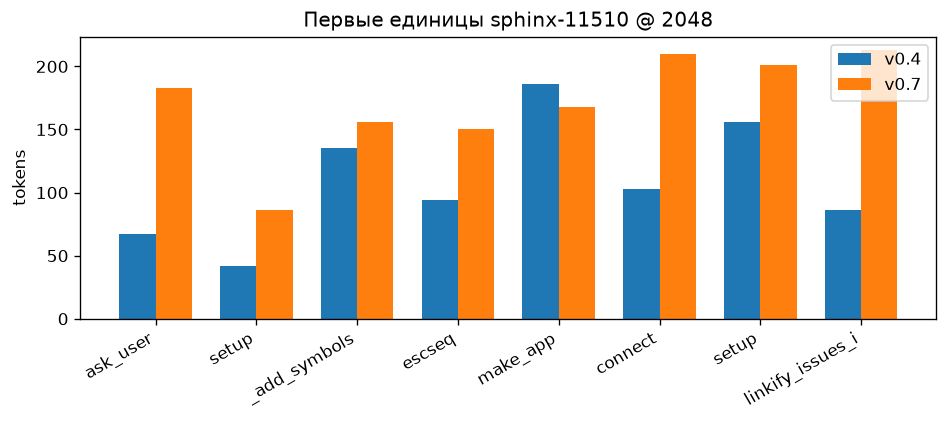

In [2]:
import gzip, json
from codegraph_rag.experiments import diagnostic_stem
iid='sphinx-doc__sphinx-11510'
def load(method):
    path=ROOT/'output/v07_dev/diagnostics'/f'{diagnostic_stem(iid,method,2048)}.json.gz'
    with gzip.open(path,'rt') as handle:
        return json.load(handle)
def openings(doc):
    rows=[]; seen=set()
    for item in doc['candidates']:
        if not item.get('selected') or item['path'] in seen:
            continue
        seen.add(item['path'])
        rows.append(item)
    return rows
a,b=openings(load('pathpack-v4')),openings(load('pathpack-v7'))
print('opening tokens v0.4', sum(item['tokens_est'] for item in a), 'files', len(a))
print('opening tokens v0.7', sum(item['tokens_est'] for item in b), 'files', len(b))
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(8,3.6))
n=min(len(a),len(b),8)
ax.bar([i-0.18 for i in range(n)], [a[i]['tokens_est'] for i in range(n)], width=0.36, label='v0.4')
ax.bar([i+0.18 for i in range(n)], [b[i]['tokens_est'] for i in range(n)], width=0.36, label='v0.7')
ax.set_xticks(range(n))
ax.set_xticklabels([b[i]['qualname'].split('.')[-1][:16] for i in range(n)], rotation=30, ha='right')
ax.set_ylabel('tokens')
ax.set_title('Первые единицы sphinx-11510 @ 2048')
ax.legend()
fig.tight_layout()


## Качество и бюджет

Кривые читают `output/v07_dev/summary.csv`. BM25, Graph Expansion, v0.5.1 и v0.6 взяты из `output/v06_dev` на тех же задачах.


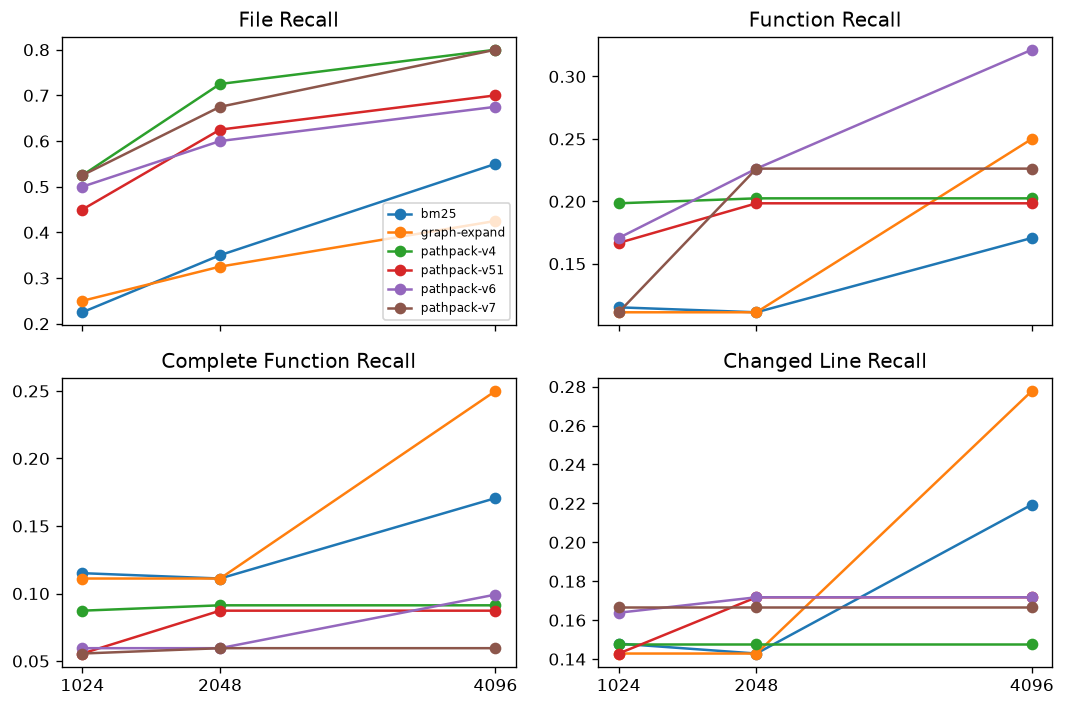

In [3]:
import csv
from collections import defaultdict
def rows(path):
    with open(ROOT/path) as handle:
        return list(csv.DictReader(handle))
dev=rows('output/v07_dev/summary.csv')
old=rows('output/v06_dev/summary.csv')
metrics=[('file_recall','File Recall'),('function_recall','Function Recall'),
         ('complete_function_recall','Complete Function Recall'),('changed_line_recall','Changed Line Recall')]
series={'bm25':'output/v06_dev','graph-expand':'output/v06_dev','pathpack-v4':'output/v07_dev',
        'pathpack-v51':'output/v06_dev','pathpack-v6':'output/v06_dev','pathpack-v7':'output/v07_dev'}
fig,axes=plt.subplots(2,2,figsize=(9,6),sharex=True)
for ax,(key,title) in zip(axes.ravel(),metrics):
    for method,source in series.items():
        table=dev if source.endswith('v07_dev') else old
        pts=[(int(row['budget']), float(row[key])) for row in table if row['method']==method]
        pts.sort()
        ax.plot([p[0] for p in pts],[p[1] for p in pts], marker='o', label=method)
    ax.set_title(title); ax.set_xticks([1024,2048,4096])
axes[0,0].legend(fontsize=7)
fig.tight_layout()


## Абляции при 2048

`no-hierarchy` повторяет v0.4. `no-adaptive` совпадает с полным v0.7: слияние функций короче 192 токенов ничего не меняет.


pair                                       metric                           diff                     ci W/T/L
pathpack-v7 - pathpack-v4                  file_recall                   -0.0500 [ -0.150,   0.000] 0/19/1
pathpack-v7 - pathpack-v4                  function_recall                0.0238 [ -0.083,   0.167] 1/15/2
pathpack-v7 - pathpack-v4                  complete_function_recall      -0.0317 [ -0.087,   0.000] 0/16/2
pathpack-v7 - pathpack-v4                  changed_line_recall            0.0187 [ -0.015,   0.071] 1/12/1
pathpack-v7/no-budget - pathpack-v4        file_recall                   -0.0500 [ -0.150,   0.000] 0/19/1
pathpack-v7/no-budget - pathpack-v4        function_recall                0.0794 [ -0.060,   0.270] 2/14/2
pathpack-v7/no-budget - pathpack-v4        complete_function_recall      -0.0317 [ -0.087,   0.000] 0/16/2
pathpack-v7/no-budget - pathpack-v4        changed_line_recall            0.1616 [  0.000,   0.357] 3/10/1


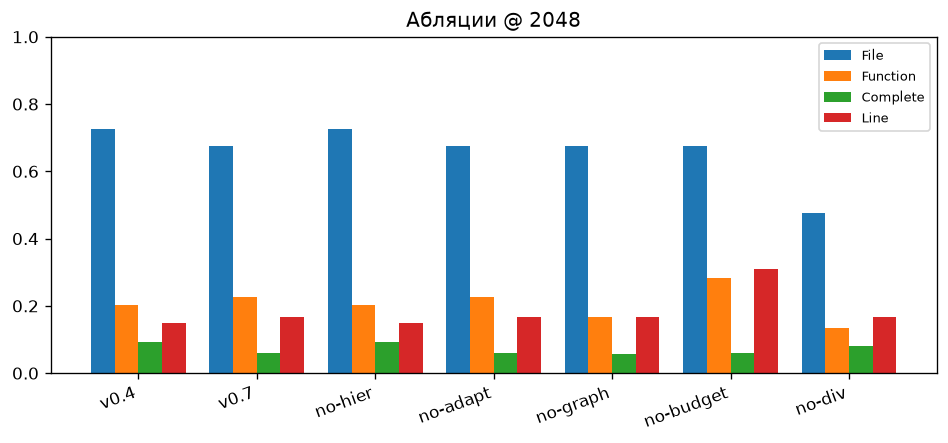

In [4]:
order=['pathpack-v4','pathpack-v7','pathpack-v7/no-hierarchy','pathpack-v7/no-adaptive',
       'pathpack-v7/no-graph','pathpack-v7/no-budget','pathpack-v7/no-diversity']
at={row['method']:row for row in dev if row['budget']=='2048'}
fig,ax=plt.subplots(figsize=(8,3.8))
import numpy as np
x=np.arange(len(order)); width=0.2
for offset,key,label in ((-1.5,'file_recall','File'),(-0.5,'function_recall','Function'),
                         (0.5,'complete_function_recall','Complete'),(1.5,'changed_line_recall','Line')):
    ax.bar(x+offset*width, [float(at[name][key]) for name in order], width=width, label=label)
ax.set_xticks(x)
ax.set_xticklabels(['v0.4','v0.7','no-hier','no-adapt','no-graph','no-budget','no-div'], rotation=20, ha='right')
ax.set_ylim(0,1); ax.legend(fontsize=8); ax.set_title('Абляции @ 2048')
fig.tight_layout()
from codegraph_rag.audit import paired_bootstrap
import json
scores=[json.loads(line) for line in open(ROOT/'output/v07_dev/scores.jsonl')]
by=defaultdict(dict)
for row in scores:
    if row['budget']==2048:
        by[row['method']][row['instance_id']]=row
print(f"{'pair':<42} {'metric':<28} {'diff':>8} {'ci':>22} W/T/L")
for candidate,baseline in (('pathpack-v7','pathpack-v4'),('pathpack-v7/no-budget','pathpack-v4')):
    for metric in ('file_recall','function_recall','complete_function_recall','changed_line_recall'):
        left={i:row[metric] for i,row in by[candidate].items() if row[metric] is not None}
        right={i:row[metric] for i,row in by[baseline].items() if row[metric] is not None}
        stat=paired_bootstrap(left,right,iterations=2000,seed=42)
        lo,hi=stat['ci95']
        print(f"{candidate+' - '+baseline:<42} {metric:<28} {stat['difference']:8.4f} [{lo:7.3f}, {hi:7.3f}] {stat['wins']}/{stat['ties']}/{stat['losses']}")


## Потолок стоимости

`output/v07_cap_dev` разрешает замену только если она не дороже открывающего чанка v0.4. Четыре метрики на каждой задаче совпадают с v0.4. Контексты совпадают не все: часть замен входит, но не двигает золотые файлы, функции и строки.


In [5]:
cap=[json.loads(line) for line in open(ROOT/'output/v07_cap_dev/predictions.jsonl')]
groups=defaultdict(dict)
for row in cap:
    groups[(row['instance_id'],row['budget_est'])][row['method']]=row['context']
same=sum(item['pathpack-v4']==item['pathpack-v7'] for item in groups.values())
print('context pairs', len(groups), 'identical', same, 'different', len(groups)-same)
scores=[json.loads(line) for line in open(ROOT/'output/v07_cap_dev/scores.jsonl')]
by=defaultdict(dict)
for row in scores:
    by[(row['instance_id'],row['budget'])][row['method']]=row
moved=0
for key,item in by.items():
    for metric in ('file_recall','function_recall','complete_function_recall','changed_line_recall'):
        if item['pathpack-v4'][metric]!=item['pathpack-v7'][metric]:
            moved+=1
print('metric cells that differ', moved)


context pairs 60 identical 38 different 22
metric cells that differ 0


## Вывод

Зафиксированный v0.7 держит latency около v0.4 (0.611 с против 0.609 с в том же прогоне) и не превосходит v0.4 по File Recall и Complete Function Recall. Единственная потеря файла — `sphinx-doc__sphinx-11510`: открывающие фрагменты выросли с 1359 до 1621 токена. Потолок стоимости возвращает метрики к v0.4. Holdout не запускался. `configs/pathpack_v07.yaml` после прогона не менялся.
